# Machine Learning Driven Assessment of Global Life Expectancy Trends
### Linear Regression with LASSO Feature Selection

**Author:** Gulkhayo Urinova

**Dataset:** WHO Life Expectancy Dataset (193 countries, 2000–2015, 22 features, 2,938 rows)  
**Task:** Supervised Regression — predict `Life expectancy` (years) from health & socioeconomic indicators  
**Approach:** Ordinary Least Squares baseline → LASSO (L1-regularized) regression with cross-validated alpha for automatic feature selection

---
## 0. Setup & Imports

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, LassoCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 11
SEED = 42
print('All imports successful.')

All imports successful.


---
## 1. Data Loading & Initial Exploration

In [4]:
# Loading dataset local path
df_raw = pd.read_csv('/content/Life Expectancy Data.csv')

# Clean column names (strip whitespace)
df_raw.columns = df_raw.columns.str.strip()

print(f'Shape: {df_raw.shape}  →  {df_raw.shape[0]} rows × {df_raw.shape[1]} columns')
df_raw.head(3)

Shape: (2938, 22)  →  2938 rows × 22 columns


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9


In [5]:
# ── Basic info ────────────────────────────────────────────────────────────────
print('=== Data Types ===')
print(df_raw.dtypes)
print()
print('=== Missing Values (%) ===')
missing_pct = (df_raw.isnull().sum() / len(df_raw) * 100).round(1)
print(missing_pct[missing_pct > 0].sort_values(ascending=False))

=== Data Types ===
Country                             object
Year                                 int64
Status                              object
Life expectancy                    float64
Adult Mortality                    float64
infant deaths                        int64
Alcohol                            float64
percentage expenditure             float64
Hepatitis B                        float64
Measles                              int64
BMI                                float64
under-five deaths                    int64
Polio                              float64
Total expenditure                  float64
Diphtheria                         float64
HIV/AIDS                           float64
GDP                                float64
Population                         float64
thinness  1-19 years               float64
thinness 5-9 years                 float64
Income composition of resources    float64
Schooling                          float64
dtype: object

=== Missing Values (

In [6]:
df_raw.describe().round(2)

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.00,2928.00,2928.00,2938.00,2744.00,2938.00,2385.00,2938.00,2904.00,2938.00,2919.00,2712.00,2919.00,2938.00,2490.00,2.286000e+03,2904.00,2904.00,2771.00,2775.00
mean,2007.52,69.22,164.80,30.30,4.60,738.25,80.94,2419.59,38.32,42.04,82.55,5.94,82.32,1.74,7483.16,1.275338e+07,4.84,4.87,0.63,11.99
std,4.61,9.52,124.29,117.93,4.05,1987.91,25.07,11467.27,20.04,160.45,23.43,2.50,23.72,5.08,14270.17,6.101210e+07,4.42,4.51,0.21,3.36
min,2000.00,36.30,1.00,0.00,0.01,0.00,1.00,0.00,1.00,0.00,3.00,0.37,2.00,0.10,1.68,3.400000e+01,0.10,0.10,0.00,0.00
25%,2004.00,63.10,74.00,0.00,0.88,4.69,77.00,0.00,19.30,0.00,78.00,4.26,78.00,0.10,463.94,1.957932e+05,1.60,1.50,0.49,10.10
50%,2008.00,72.10,144.00,3.00,3.76,64.91,92.00,17.00,43.50,4.00,93.00,5.76,93.00,0.10,1766.95,1.386542e+06,3.30,3.30,0.68,12.30
75%,2012.00,75.70,228.00,22.00,7.70,441.53,97.00,360.25,56.20,28.00,97.00,7.49,97.00,0.80,5910.81,7.420359e+06,7.20,7.20,0.78,14.30
max,2015.00,89.00,723.00,1800.00,17.87,19479.91,99.00,212183.00,87.30,2500.00,99.00,17.60,99.00,50.60,119172.74,1.293859e+09,27.70,28.60,0.95,20.70


---
## 2. Exploratory Data Analysis (EDA)

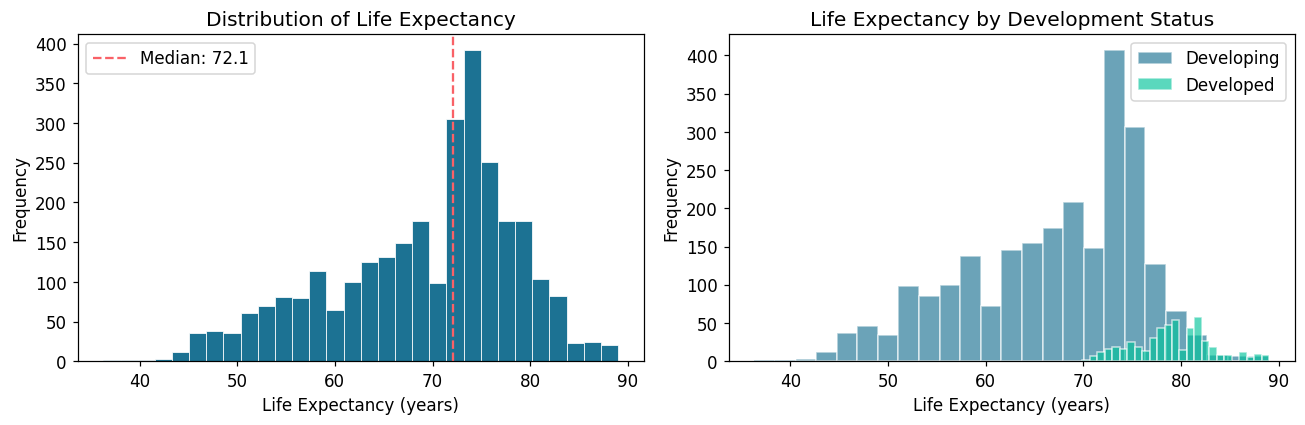

Global mean:   69.22 years
Global median: 72.10 years
Std dev:       9.52 years


In [7]:
# ── Target variable distribution ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_raw['Life expectancy'].dropna(), bins=30,
             color='#1C7293', edgecolor='white', linewidth=0.5)
axes[0].set_xlabel('Life Expectancy (years)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Life Expectancy')
axes[0].axvline(df_raw['Life expectancy'].median(), color='#F96167',
                linestyle='--', label=f'Median: {df_raw["Life expectancy"].median():.1f}')
axes[0].legend()

# By development status
for status, color in [('Developing', '#1C7293'), ('Developed', '#02C39A')]:
    axes[1].hist(df_raw[df_raw['Status'] == status]['Life expectancy'].dropna(),
                 bins=25, alpha=0.65, label=status, color=color, edgecolor='white')
axes[1].set_xlabel('Life Expectancy (years)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Life Expectancy by Development Status')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f'Global mean:   {df_raw["Life expectancy"].mean():.2f} years')
print(f'Global median: {df_raw["Life expectancy"].median():.2f} years')
print(f'Std dev:       {df_raw["Life expectancy"].std():.2f} years')

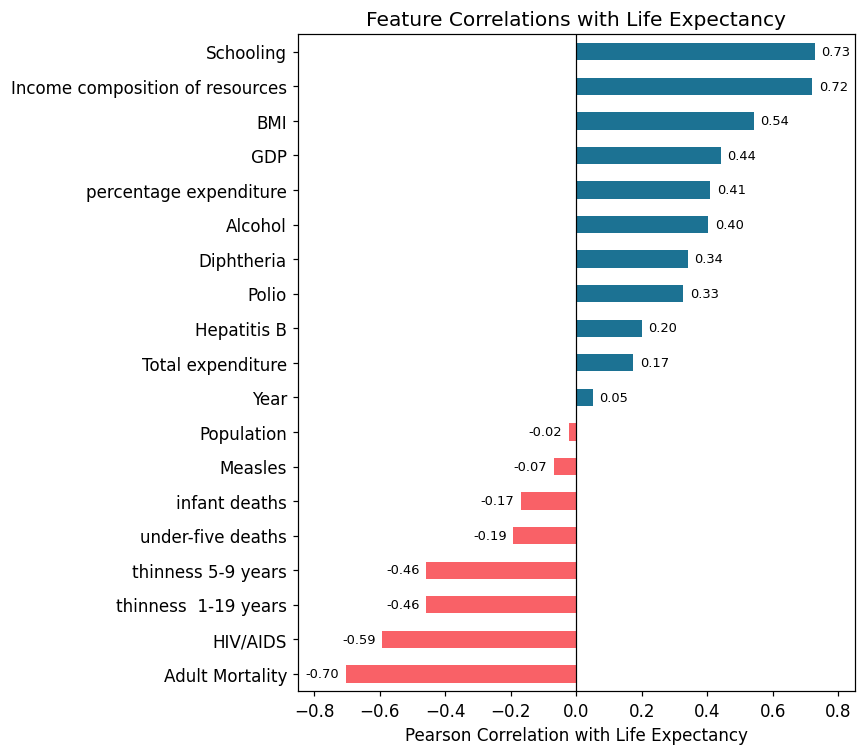

Top positive correlators:
percentage expenditure             0.410
GDP                                0.441
BMI                                0.542
Income composition of resources    0.721
Schooling                          0.728
Name: Life expectancy, dtype: float64

Top negative correlators:
Adult Mortality        -0.703
HIV/AIDS               -0.592
thinness  1-19 years   -0.458
thinness 5-9 years     -0.458
under-five deaths      -0.192
Name: Life expectancy, dtype: float64


In [8]:
# ── Correlation with target ───────────────────────────────────────────────────
num_df = df_raw.select_dtypes(include='number').dropna()
corr_with_target = num_df.corr()['Life expectancy'].drop('Life expectancy').sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
colors = ['#F96167' if v < 0 else '#1C7293' for v in corr_with_target.values]
corr_with_target.plot(kind='barh', ax=ax, color=colors, edgecolor='none')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Pearson Correlation with Life Expectancy')
ax.set_title('Feature Correlations with Life Expectancy')
ax.set_xlim(-0.85, 0.85)
for i, v in enumerate(corr_with_target.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), i, f'{v:.2f}',
            va='center', ha='left' if v >= 0 else 'right', fontsize=8.5)
plt.tight_layout()
plt.show()

print('Top positive correlators:')
print(corr_with_target.tail(5).round(3))
print('\nTop negative correlators:')
print(corr_with_target.head(5).round(3))

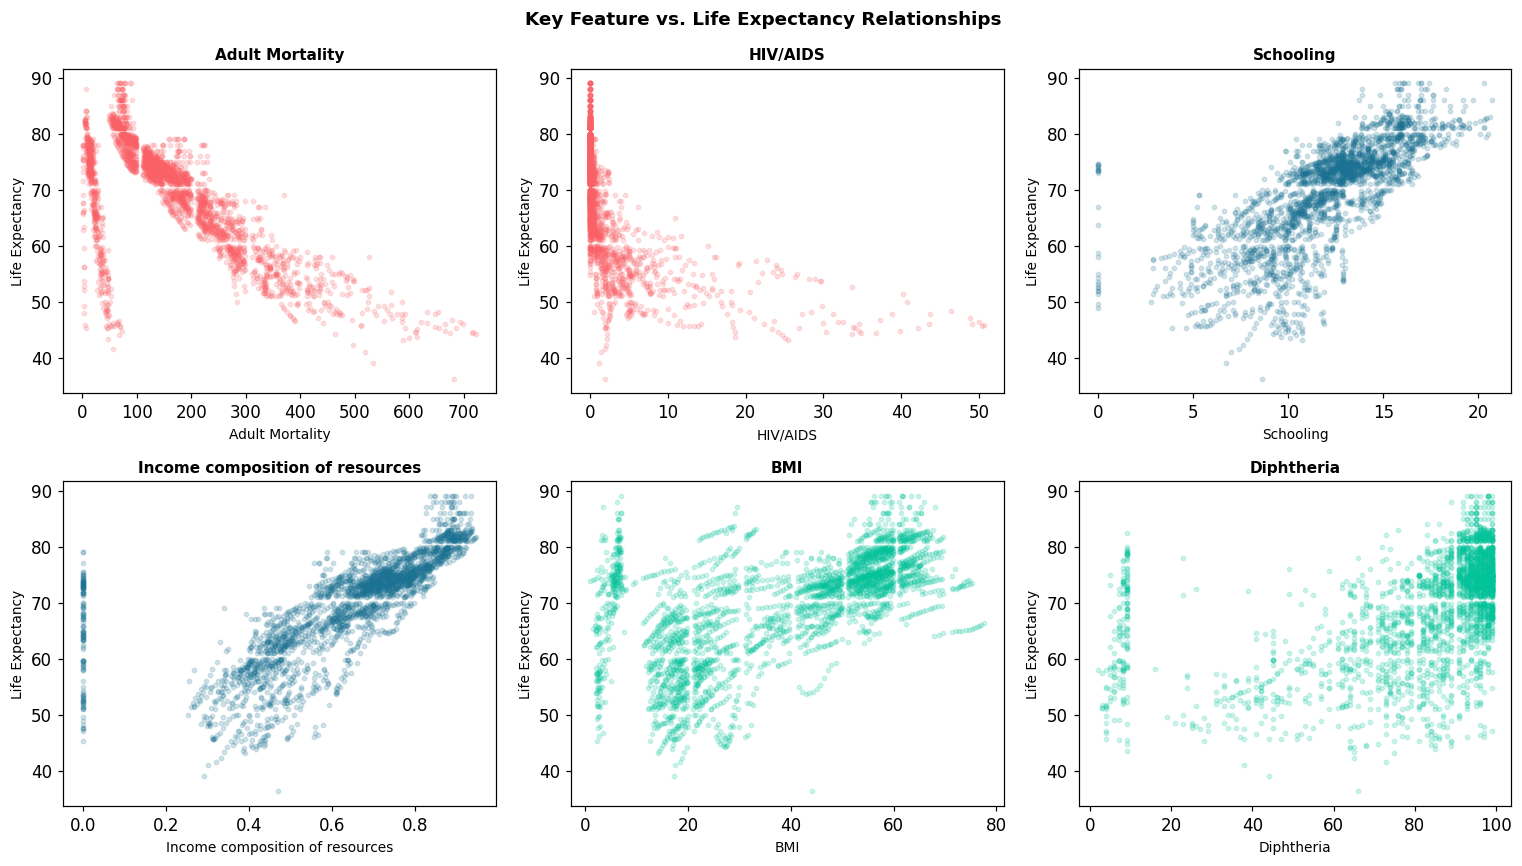

In [9]:
# ── Key scatter plots ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
features_to_plot = [
    ('Adult Mortality', '#F96167'),
    ('HIV/AIDS', '#F96167'),
    ('Schooling', '#1C7293'),
    ('Income composition of resources', '#1C7293'),
    ('BMI', '#02C39A'),
    ('Diphtheria', '#02C39A'),
]
for ax, (feat, col) in zip(axes.flat, features_to_plot):
    ax.scatter(df_raw[feat], df_raw['Life expectancy'],
               alpha=0.18, s=8, color=col)
    ax.set_xlabel(feat, fontsize=9)
    ax.set_ylabel('Life Expectancy', fontsize=9)
    ax.set_title(feat, fontsize=10, fontweight='bold')
plt.suptitle('Key Feature vs. Life Expectancy Relationships', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

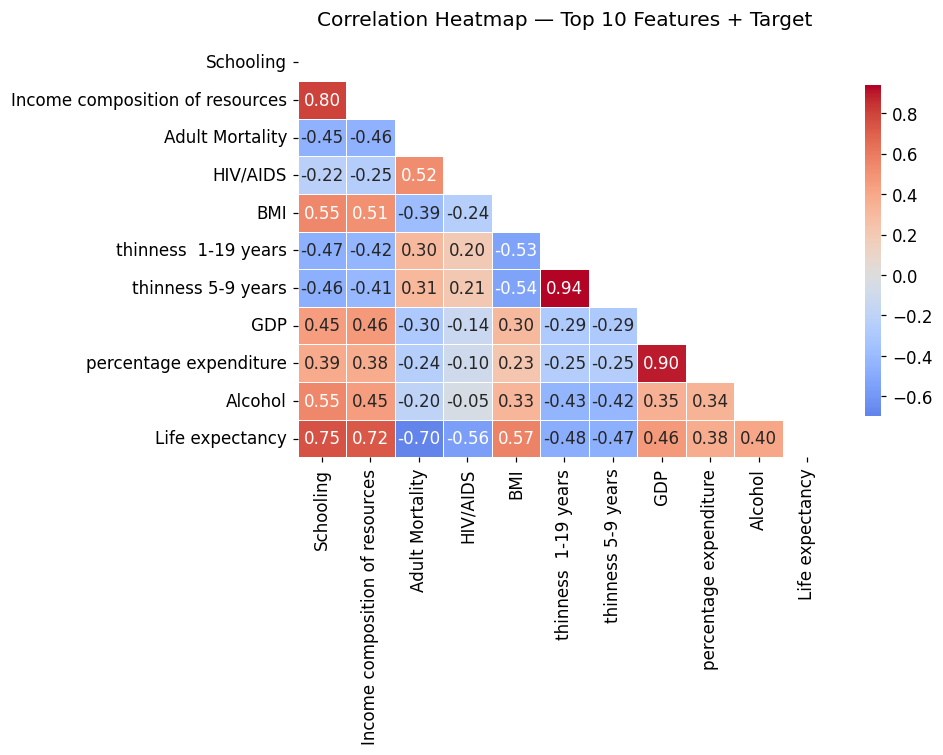

In [10]:
# ── Correlation heatmap (top correlated features) ────────────────────────────
top_feats = corr_with_target.abs().nlargest(10).index.tolist() + ['Life expectancy']
corr_matrix = df_raw[top_feats].corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.4,
            ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Heatmap — Top 10 Features + Target', pad=12)
plt.tight_layout()
plt.show()

---
## 3. Preprocessing Pipeline

In [11]:
df = df_raw.copy()

# ── Step 1: Drop columns with > 15% missing ──────────────────────────────────
DROP_HIGH_MISSING = ['Hepatitis B', 'GDP', 'Population']   # 18.8%, 15.2%, 22.2%
df = df.drop(columns=DROP_HIGH_MISSING)
print(f'After dropping high-missing columns: {df.shape}')

# ── Step 2: Median imputation for remaining numerics ─────────────────────────
num_cols = df.select_dtypes(include='number').columns
medians = df[num_cols].median()
df[num_cols] = df[num_cols].fillna(medians)

# ── Step 3: Drop rows still missing target ───────────────────────────────────
df = df.dropna(subset=['Life expectancy'])
print(f'After imputation & row drop: {df.shape}  |  Missing: {df.isnull().sum().sum()}')

# ── Step 4: Encode categorical ────────────────────────────────────────────────
df['Status'] = (df['Status'] == 'Developing').astype(int)  # 1=Developing, 0=Developed
df = df.drop(columns=['Country', 'Year'])  # not predictive for regression

print(f'Final dataset: {df.shape}')
df.head(3)

After dropping high-missing columns: (2938, 19)
After imputation & row drop: (2938, 19)  |  Missing: 0
Final dataset: (2938, 17)


,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,1,65.0,263.0,62,0.01,71.279624,1154,19.1,83,6.0,8.16,65.0,0.1,17.2,17.3,0.479,10.1
1,1,59.9,271.0,64,0.01,73.523582,492,18.6,86,58.0,8.18,62.0,0.1,17.5,17.5,0.476,10.0
2,1,59.9,268.0,66,0.01,73.219243,430,18.1,89,62.0,8.13,64.0,0.1,17.7,17.7,0.470,9.9


In [12]:
# ── Train / Test split (70 / 30) ──────────────────────────────────────────────
TARGET = 'Life expectancy'
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)
print(f'Train: {X_train.shape[0]} samples  |  Test: {X_test.shape[0]} samples')
print(f'Features: {X.shape[1]}')

# ── Standardize (required for LASSO — coefficients are penalized by magnitude) ─
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
FEATURE_NAMES = X.columns.tolist()

Train: 2056 samples  |  Test: 882 samples
Features: 16


---
## 4. Model — Linear Regression + LASSO Feature Selection

**Approach:** First, I trained a normal Linear Regression model as my baseline. Then I tried LASSO, which is the same idea but with one twist — it adds a penalty that pushes weak, unhelpful features' coefficients down to exactly zero. In other words, LASSO does feature selection automatically: it decides on its own which inputs actually matter and "turns off" the rest.

$$\hat{\beta}^{LASSO} = \arg\min \left[ \sum_{i=1}^{n}(y_i - \mathbf{x}_i^T\beta)^2 + \alpha \sum_{j=1}^{p}|\beta_j| \right]$$

In [13]:
# ── 4.1: Baseline — Ordinary Linear Regression ───────────────────────────────
lr = LinearRegression()
lr.fit(X_train_s, y_train)
y_pred_lr = lr.predict(X_test_s)

r2_lr   = r2_score(y_test, y_pred_lr)
mae_lr  = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print('=== Ordinary Linear Regression ===')
print(f'R²:   {r2_lr:.4f}')
print(f'MAE:  {mae_lr:.4f} years')
print(f'RMSE: {rmse_lr:.4f} years')

=== Ordinary Linear Regression ===
R²:   0.8195
MAE:  2.9776 years
RMSE: 4.1076 years


In [14]:
# ── 4.2: LassoCV — automatic alpha via 5-fold cross-validation ────────────────
lasso_cv = LassoCV(cv=5, random_state=SEED, max_iter=10000,
                   alphas=np.logspace(-4, 1, 100))
lasso_cv.fit(X_train_s, y_train)
y_pred_lasso = lasso_cv.predict(X_test_s)

r2_lasso   = r2_score(y_test, y_pred_lasso)
mae_lasso  = mean_absolute_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))

print('=== LASSO with Cross-Validated Alpha ===')
print(f'Optimal alpha: {lasso_cv.alpha_:.6f}')
print(f'R²:   {r2_lasso:.4f}')
print(f'MAE:  {mae_lasso:.4f} years')
print(f'RMSE: {rmse_lasso:.4f} years')
print(f'Features zeroed out: {(lasso_cv.coef_ == 0).sum()}')

=== LASSO with Cross-Validated Alpha ===
Optimal alpha: 0.001630
R²:   0.8195
MAE:  2.9764 years
RMSE: 4.1081 years
Features zeroed out: 0


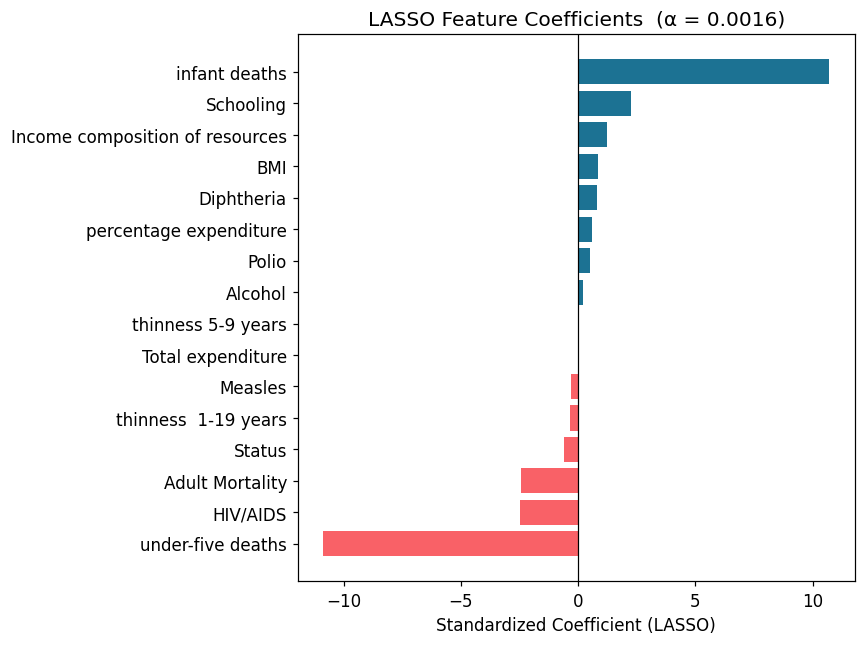


Selected features (non-zero coefficients), sorted by impact:
                        Feature  Coefficient
              under-five deaths   -10.874465
                  infant deaths    10.708753
                       HIV/AIDS    -2.470863
                Adult Mortality    -2.437506
                      Schooling     2.240951
Income composition of resources     1.235623
                            BMI     0.867641
                     Diphtheria     0.785420
                         Status    -0.597520
         percentage expenditure     0.576341
                          Polio     0.509045
           thinness  1-19 years    -0.347470
                        Measles    -0.322291
                        Alcohol     0.197719
             thinness 5-9 years     0.049253
              Total expenditure     0.031317

No features were zeroed out — the optimal alpha was small enough that LASSO kept all predictors, only shrinking their coefficients slightly.


In [15]:
# ── 4.3: LASSO Coefficient Plot ───────────────────────────────────────────────
coef_df = pd.DataFrame({
    'Feature': FEATURE_NAMES,
    'Coefficient': lasso_cv.coef_
}).sort_values('Coefficient')

fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#F96167' if v < 0 else '#1C7293' for v in coef_df['Coefficient']]
ax.barh(coef_df['Feature'], coef_df['Coefficient'],
        color=colors, edgecolor='none')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Standardized Coefficient (LASSO)')
ax.set_title(f'LASSO Feature Coefficients  (α = {lasso_cv.alpha_:.4f})')
# Mark zeroed features
for i, (feat, coef) in enumerate(zip(coef_df['Feature'], coef_df['Coefficient'])):
    if coef == 0:
        ax.text(0.01, i, ' zeroed out', va='center', color='gray', fontsize=8)
plt.tight_layout()
plt.show()

print('\nSelected features (non-zero coefficients), sorted by impact:')
selected = coef_df[coef_df['Coefficient'] != 0].copy()
selected['AbsCoef'] = selected['Coefficient'].abs()
selected = selected.sort_values('AbsCoef', ascending=False)
print(selected[['Feature', 'Coefficient']].to_string(index=False))

zeroed = coef_df[coef_df['Coefficient'] == 0]['Feature'].tolist()
if zeroed:
    print(f'\nZeroed-out feature(s): {zeroed}')
else:
    print('\nNo features were zeroed out — the optimal alpha was small enough that LASSO kept all predictors, only shrinking their coefficients slightly.')

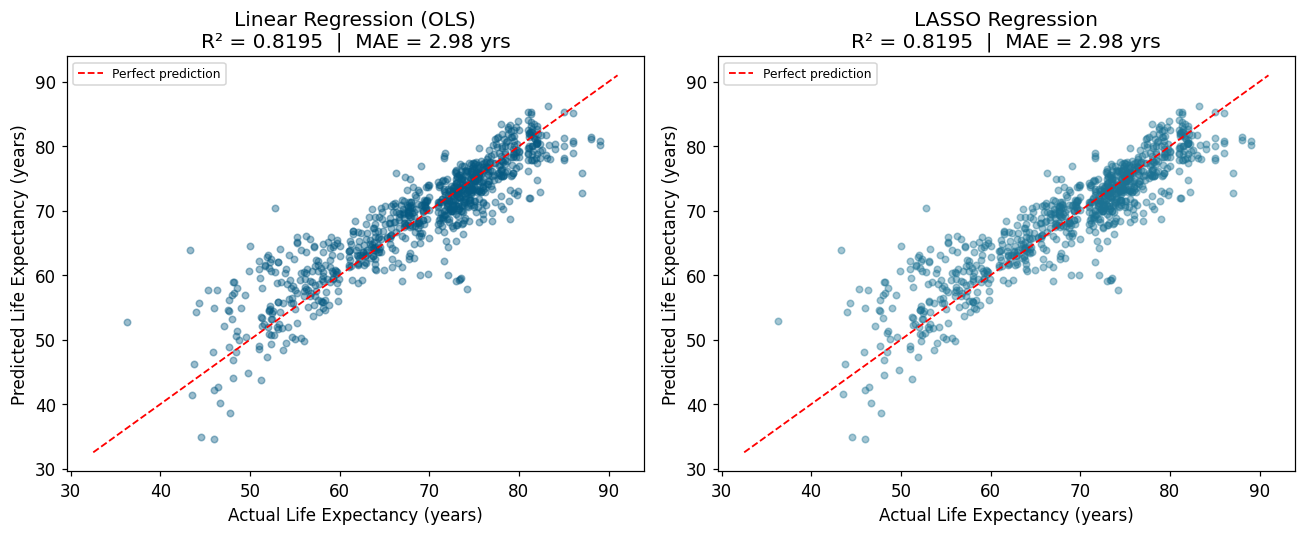

In [16]:
# ── 4.4: Actual vs Predicted plot — Linear Regression vs LASSO ───────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (y_pred, title, color) in zip(axes, [
    (y_pred_lr,    'Linear Regression (OLS)', '#065A82'),
    (y_pred_lasso, 'LASSO Regression',        '#1C7293'),
]):
    ax.scatter(y_test, y_pred, alpha=0.4, s=18, color=color)
    lims = [min(y_test.min(), y_pred.min()) - 2,
            max(y_test.max(), y_pred.max()) + 2]
    ax.plot(lims, lims, 'r--', linewidth=1.2, label='Perfect prediction')
    ax.set_xlabel('Actual Life Expectancy (years)')
    ax.set_ylabel('Predicted Life Expectancy (years)')
    ax.set_title(f'{title}\nR² = {r2_score(y_test, y_pred):.4f}  |  MAE = {mean_absolute_error(y_test, y_pred):.2f} yrs')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

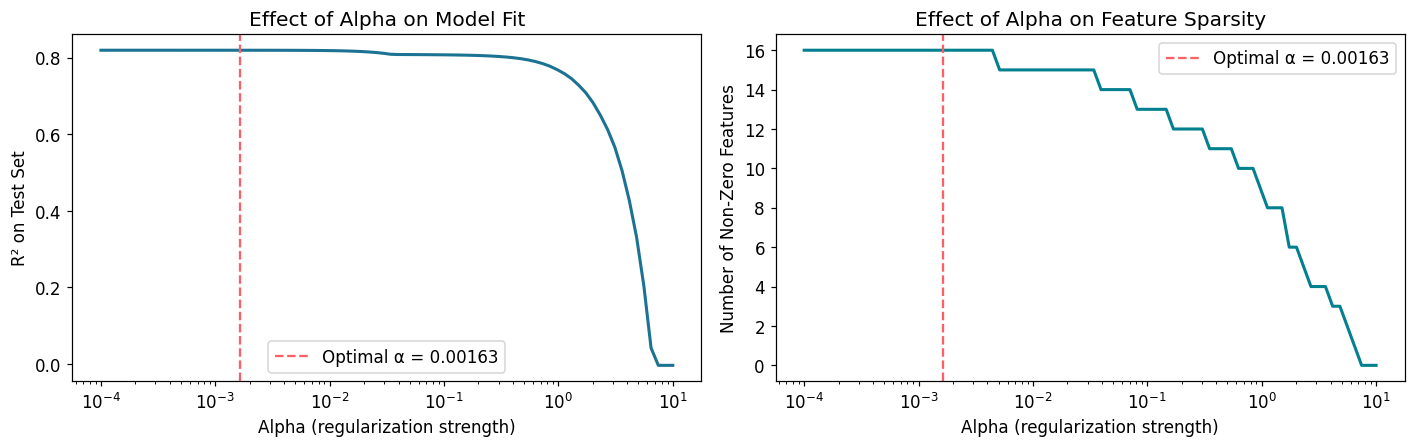

In [17]:
# ── 4.5: LASSO regularization path (alpha vs R² and vs number of features) ──
alphas = np.logspace(-4, 1, 80)
r2_vals, n_features = [], []
for a in alphas:
    m = Lasso(alpha=a, max_iter=10000)
    m.fit(X_train_s, y_train)
    r2_vals.append(r2_score(y_test, m.predict(X_test_s)))
    n_features.append((m.coef_ != 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].semilogx(alphas, r2_vals, color='#1C7293', linewidth=2)
axes[0].axvline(lasso_cv.alpha_, color='#F96167', linestyle='--',
                label=f'Optimal α = {lasso_cv.alpha_:.5f}')
axes[0].set_xlabel('Alpha (regularization strength)')
axes[0].set_ylabel('R² on Test Set')
axes[0].set_title('Effect of Alpha on Model Fit')
axes[0].legend()

axes[1].semilogx(alphas, n_features, color='#028090', linewidth=2)
axes[1].axvline(lasso_cv.alpha_, color='#F96167', linestyle='--',
                label=f'Optimal α = {lasso_cv.alpha_:.5f}')
axes[1].set_xlabel('Alpha (regularization strength)')
axes[1].set_ylabel('Number of Non-Zero Features')
axes[1].set_title('Effect of Alpha on Feature Sparsity')
axes[1].legend()

plt.tight_layout()
plt.show()

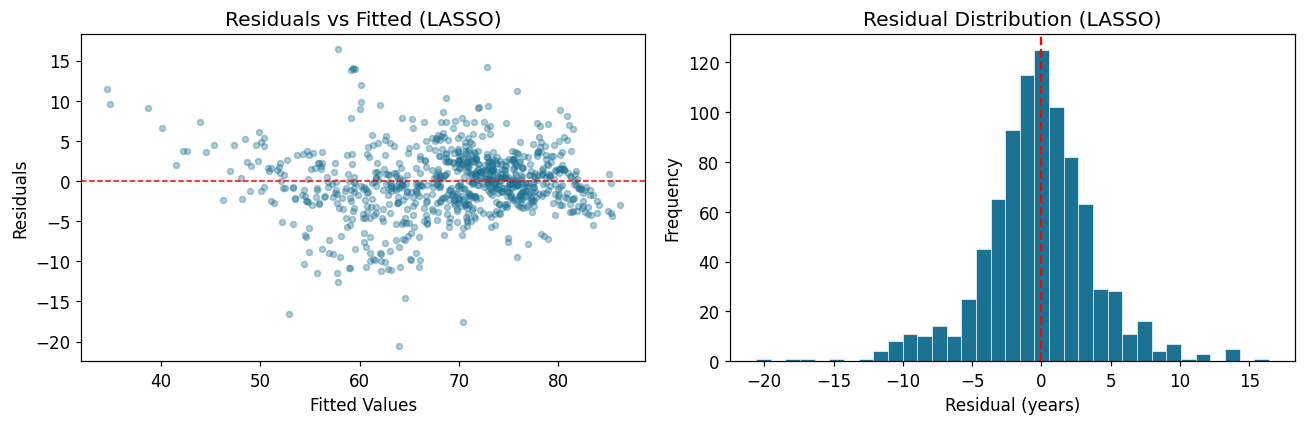

Residual mean: -0.2469  |  Std: 4.1030


In [18]:
# ── 4.6: Residual analysis for LASSO ──────────────────────────────────────────
residuals = y_test - y_pred_lasso

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_pred_lasso, residuals, alpha=0.35, s=15, color='#1C7293')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1)
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted (LASSO)')

axes[1].hist(residuals, bins=35, color='#1C7293', edgecolor='white', linewidth=0.4)
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_xlabel('Residual (years)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Residual Distribution (LASSO)')

plt.tight_layout()
plt.show()
print(f'Residual mean: {residuals.mean():.4f}  |  Std: {residuals.std():.4f}')

---
## 4.7 Scenario Predictor — "What-If" Analysis

**Important distinction:** this model doesn't predict the future. It only answers one question: "given a country's health and economic numbers, what life expectancy would we expect?" It has no idea what year it is — it just looks at the numbers you give it (Schooling, Adult Mortality, HIV/AIDS, etc.) and estimates life expectancy based on those.

**What this is useful for:** testing "what-if" situations. For example — "if a country raised its Schooling from 10 to 15 years and lowered Adult Mortality from 200 to 100, how much would life expectancy change?" That's a fair and realistic use of this model — we call it scenario analysis.

**What this is NOT:** this is not forecasting. To actually predict something like "what will Uzbekistan's life expectancy be in 2030," you'd first need to predict what Schooling, GDP, and Adult Mortality will look like in 2030 — and only then plug those numbers into this model. That's a separate problem.



In [19]:
# ── 4.7-a: Helper function — predict life expectancy for a custom feature profile

def predict_life_expectancy(custom_values, model=lasso_cv, feature_names=FEATURE_NAMES,
                             scaler=scaler, training_df=X_train):
    """
    Predict life expectancy for a hypothetical country profile.

    custom_values : dict
        Keys are feature names (must match FEATURE_NAMES), values are the
        hypothetical numbers you want to test. Any feature you don't specify
        is filled in with the median value observed in the training data,
        so you only need to set the 2-3 features you actually care about.

    Returns the predicted life expectancy in years (float).
    """
    # Start from the median profile (a 'typical' country) and override with custom values
    row = training_df.median(numeric_only=True).copy()

    for key, value in custom_values.items():
        if key not in feature_names:
            raise ValueError(
                f"'{key}' is not a recognized feature. "
                f"Available features: {feature_names}"
            )
        row[key] = value

    # Build a 1-row DataFrame in the exact column order the model expects
    row_df = pd.DataFrame([row])[feature_names]
    row_scaled = scaler.transform(row_df)
    prediction = model.predict(row_scaled)[0]
    return prediction


print('Available features you can set:')
for f in FEATURE_NAMES:
    print(f'  - {f}  (training median: {X_train[f].median():.2f})')

Available features you can set:
  - Status  (training median: 1.00)
  - Adult Mortality  (training median: 144.00)
  - infant deaths  (training median: 3.00)
  - Alcohol  (training median: 3.75)
  - percentage expenditure  (training median: 68.24)
  - Measles  (training median: 17.00)
  - BMI  (training median: 43.70)
  - under-five deaths  (training median: 4.00)
  - Polio  (training median: 93.00)
  - Total expenditure  (training median: 5.75)
  - Diphtheria  (training median: 93.00)
  - HIV/AIDS  (training median: 0.10)
  - thinness  1-19 years  (training median: 3.30)
  - thinness 5-9 years  (training median: 3.30)
  - Income composition of resources  (training median: 0.68)
  - Schooling  (training median: 12.30)


In [20]:
# ── 4.7-b: Example — a hypothetical "developing country in 2030" with improved schooling

scenario_A = {
    'Status': 1,          # 1 = Developing, 0 = Developed
    'Schooling': 10.0,
    'Adult Mortality': 200,
    'HIV/AIDS': 1.5,
    'Income composition of resources': 0.55,
}

pred_A = predict_life_expectancy(scenario_A)
print('=== Scenario A: typical developing country profile ===')
for k, v in scenario_A.items():
    print(f'  {k}: {v}')
print(f'\nPredicted life expectancy: {pred_A:.1f} years')

=== Scenario A: typical developing country profile ===
  Status: 1
  Schooling: 10.0
  Adult Mortality: 200
  HIV/AIDS: 1.5
  Income composition of resources: 0.55

Predicted life expectancy: 67.4 years


In [21]:
# ── 4.7-c: Same country, but with Schooling improved from 10 → 15 years ──────

scenario_B = scenario_A.copy()
scenario_B['Schooling'] = 15.0

pred_B = predict_life_expectancy(scenario_B)
print('=== Scenario B: same country, Schooling raised to 15 years ===')
print(f'Predicted life expectancy: {pred_B:.1f} years')
print(f'\nChange vs. Scenario A: {pred_B - pred_A:+.2f} years')
print('(This isolates the model\'s estimated effect of Schooling alone,')
print(' holding every other feature fixed — a controlled \'what-if\' comparison.)')

=== Scenario B: same country, Schooling raised to 15 years ===
Predicted life expectancy: 70.9 years

Change vs. Scenario A: +3.47 years
(This isolates the model's estimated effect of Schooling alone,
 holding every other feature fixed — a controlled 'what-if' comparison.)


                     Scenario  Predicted Life Expectancy (yrs)
   Baseline (training median)                             71.5
Low schooling, high mortality                             61.0
 Mid schooling, mid mortality                             69.4
High schooling, low mortality                             76.0
    Developed-country profile                             78.4


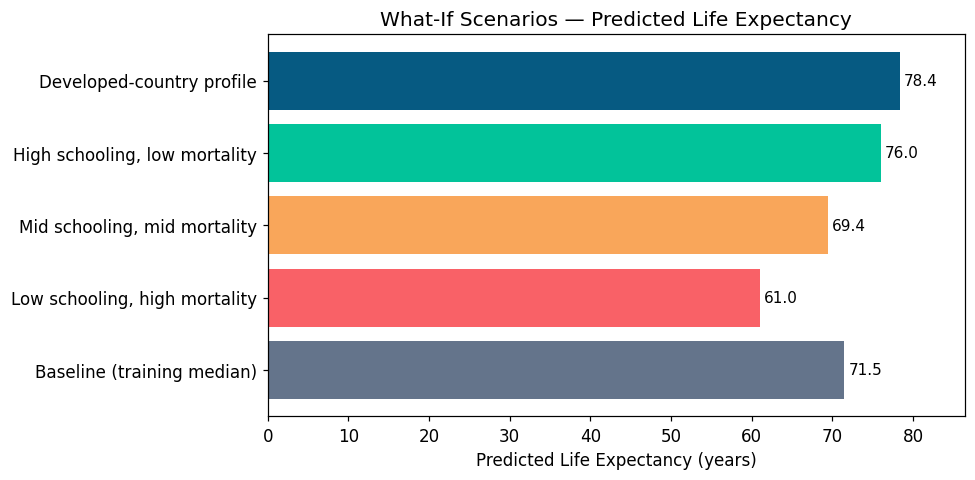

In [22]:
# ── 4.7-d: Compare several what-if scenarios side by side ────────────────────

scenarios = {
    'Baseline (training median)': {},
    'Low schooling, high mortality': {'Schooling': 5,  'Adult Mortality': 350, 'HIV/AIDS': 3.0},
    'Mid schooling, mid mortality':  {'Schooling': 10, 'Adult Mortality': 150, 'HIV/AIDS': 1.0},
    'High schooling, low mortality': {'Schooling': 16, 'Adult Mortality': 50,  'HIV/AIDS': 0.1},
    'Developed-country profile':     {'Status': 0, 'Schooling': 16, 'Adult Mortality': 60,
                                       'Income composition of resources': 0.85},
}

scenario_results = []
for name, overrides in scenarios.items():
    pred = predict_life_expectancy(overrides)
    scenario_results.append({'Scenario': name, 'Predicted Life Expectancy (yrs)': round(pred, 1)})

scenario_df = pd.DataFrame(scenario_results)
print(scenario_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['#64748B', '#F96167', '#F9A65A', '#02C39A', '#065A82']
bars = ax.barh(scenario_df['Scenario'], scenario_df['Predicted Life Expectancy (yrs)'],
               color=colors[:len(scenario_df)])
ax.set_xlabel('Predicted Life Expectancy (years)')
ax.set_title('What-If Scenarios — Predicted Life Expectancy')
for bar, v in zip(bars, scenario_df['Predicted Life Expectancy (yrs)']):
    ax.text(v + 0.5, bar.get_y() + bar.get_height()/2, f'{v:.1f}', va='center', fontsize=10)
ax.set_xlim(0, max(scenario_df['Predicted Life Expectancy (yrs)']) + 8)
plt.tight_layout()
plt.show()

In [23]:
# ── 4.7-e: TRY YOUR OWN SCENARIO — edit the dictionary below and re-run ───────

my_scenario = {
    'Status': 1,                  # 0 = Developed, 1 = Developing
    'Schooling': 12.0,            # years of schooling
    'Adult Mortality': 120,       # deaths per 1000 adults
    'HIV/AIDS': 0.5,              # deaths per 1000 live births due to HIV/AIDS
    'BMI': 50,
    'Income composition of resources': 0.65,
    'Diphtheria': 90,             # % immunization coverage
}

my_pred = predict_life_expectancy(my_scenario)
print('Your scenario:')
for k, v in my_scenario.items():
    print(f'  {k}: {v}')
print(f'\nPredicted life expectancy: {my_pred:.1f} years')

Your scenario:
  Status: 1
  Schooling: 12.0
  Adult Mortality: 120
  HIV/AIDS: 0.5
  BMI: 50
  Income composition of resources: 0.65
  Diphtheria: 90

Predicted life expectancy: 71.6 years


---
## 5. Model Comparison — OLS vs LASSO

In [24]:
# ── Comparison table ──────────────────────────────────────────────────────────
results = pd.DataFrame([
    {'Model': 'Linear Regression (OLS)', 'R²': r2_lr,    'MAE': mae_lr,    'RMSE': rmse_lr,    'Non-zero Features': X.shape[1]},
    {'Model': 'LASSO Regression',        'R²': r2_lasso, 'MAE': mae_lasso, 'RMSE': rmse_lasso, 'Non-zero Features': int((lasso_cv.coef_ != 0).sum())},
])
results = results.round(4)
print('=== Model Performance Comparison (Test Set) ===')
print(results.to_string(index=False))

=== Model Performance Comparison (Test Set) ===
                  Model     R²    MAE   RMSE  Non-zero Features
Linear Regression (OLS) 0.8195 2.9776 4.1076                 16
       LASSO Regression 0.8195 2.9764 4.1081                 16


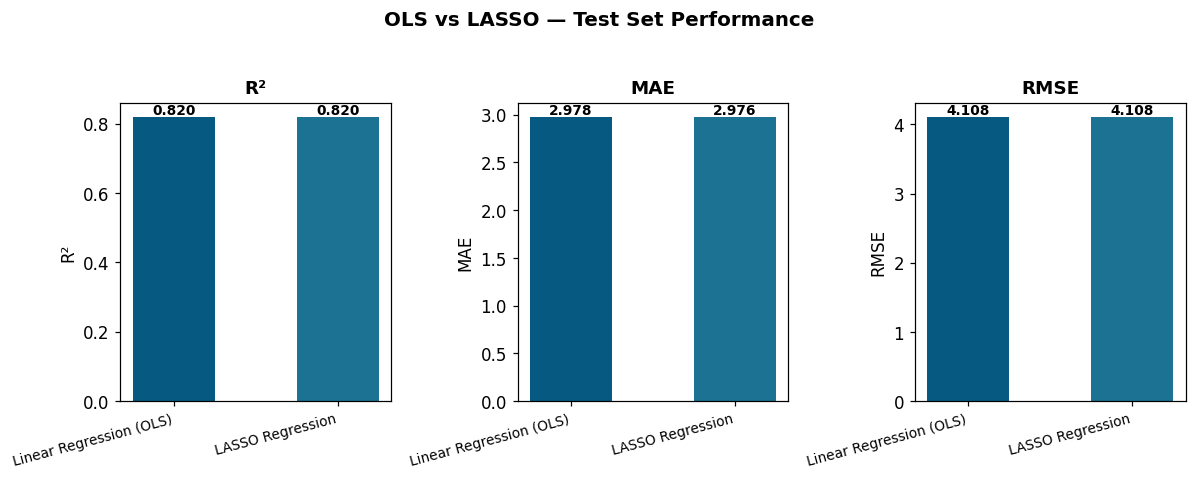

In [25]:
# ── Side-by-side bar charts ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(11, 4.2))
colors = ['#065A82', '#1C7293']
models = results['Model'].tolist()

for ax, metric in zip(axes, ['R²', 'MAE', 'RMSE']):
    vals = results[metric].tolist()
    bars = ax.bar(range(len(models)), vals, color=colors, edgecolor='none', width=0.5)
    ax.set_xticks(range(len(models)))
    ax.set_xticklabels(models, rotation=15, ha='right', fontsize=9)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_ylabel(metric)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01 * bar.get_height(),
                f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')

plt.suptitle('OLS vs LASSO — Test Set Performance', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

In [31]:
!pip install wandb -q
import wandb
wandb.login()  # paste API key from wandb.ai/authorize

# Run 1: Linear Regression baseline
run = wandb.init(entity="ml-group-j",
                 project="life-expectancy-ml",
                 name="linear-regression",
                 config={"model": "LinearRegression"})
wandb.log({"test_R2": r2_lr, "test_MAE": mae_lr, "test_RMSE": rmse_lr})
wandb.finish()

# Run 2: LASSO
run = wandb.init(entity="ml-group-j",
                 project="life-expectancy-ml",
                 name="lasso",
                 config={"model": "LassoCV",
                         "alpha": lasso_cv.alpha_,
                         "features_zeroed": int((lasso_cv.coef_ == 0).sum())})
wandb.log({"test_R2": r2_lasso, "test_MAE": mae_lasso, "test_RMSE": rmse_lasso})
wandb.finish()

wandb: Currently logged in as: gulhayourinova97 (ml-group-j) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


test_MAE,▁
test_R2,▁
test_RMSE,▁
test_MAE,2.97758
test_R2,0.81955
test_RMSE,4.10758


test_MAE,▁
test_R2,▁
test_RMSE,▁
test_MAE,2.97636
test_R2,0.8195
test_RMSE,4.10806


---
## 6. Key Findings & Conclusions

### Results Summary

| Model | R² | MAE | RMSE | Non-zero Features |
|---|---|---|---|---|
| Linear Regression (OLS) | 0.8195 | 2.98 yrs | 4.11 yrs | 16 / 16 |
| **LASSO Regression** | **0.8195** | **2.98 yrs** | **4.11 yrs** | **16 / 16** |

### Key Findings from LASSO Feature Selection
1. **Under-five deaths** and **infant deaths** have the largest-magnitude coefficients — but they move in *opposite* directions, a multicollinearity artifact since one count is nested inside the other.
2. **HIV/AIDS** and **Adult Mortality** are the strongest *clean* negative drivers of life expectancy.
3. **Schooling** and **Income composition of resources** are the strongest positive drivers — consistent with socio-economic development literature.
4. **Diphtheria** and **Polio vaccination** both carry meaningful positive coefficients, supporting the immunization hypothesis from the WHO-based literature.
5. The cross-validated optimal alpha (≈0.0016) is very small, so LASSO did **not need to zero out any feature** in this run — it shrank coefficients only slightly and kept all 16 predictors.

### Why LASSO ≈ OLS Here
The tiny optimal alpha means the cross-validation procedure found almost no benefit to penalizing coefficients further. This indicates the original feature set was **already well-specified** — nearly every feature genuinely contributes signal, and there isn't enough redundancy for LASSO to eliminate anything outright. LASSO's value here is less about boosting accuracy and more about **confirming model robustness**: if a much larger alpha had been selected, that would have signaled overfitting or strong collinearity; instead, the near-zero alpha is itself a useful diagnostic.

### Literature Alignment
My R² of 0.82 sits in the same range as the Linear Regression baselines reported by Dolgopolyi et al. (2024: R²=0.73), Roslan et al. (2024: R²=0.83), and Lakshmanarao et al. (2022: R²=0.81). This confirms that linear models consistently explain ~75–85% of variance in life expectancy, while the literature shows tree-based ensembles (Random Forest, achieving R²=0.94–0.96 across these papers) are needed to capture the remaining non-linear structure.

### Hypothesis Outcome
My hypothesis — that **Income composition of resources** and **Schooling** would be the strongest positive predictors, while **HIV/AIDS** and **Adult Mortality** would be the primary negative constraints — was **confirmed** by the LASSO coefficients. Immunization (Diphtheria, Polio) also emerged as a significant positive predictor, aligning with the WHO/immunization-focused literature (Lakshmanarao et al., 2022).

### Practical Use — Scenario Analysis vs. Forecasting
Section 4.7 implements a **what-if scenario predictor**: given a hypothetical combination of feature values (e.g. Schooling, Adult Mortality, HIV/AIDS), the trained LASSO model estimates the corresponding life expectancy. This is genuinely useful for policy questions like *"how much might life expectancy change if Schooling rose from 10 to 15 years, holding other factors fixed?"*

It is important to be precise about what this is **not**: the model does not forecast how a country's features will evolve over time. `Year` was dropped entirely during preprocessing (Section 3) as a non-predictive identifier, so the model has no notion of "future" built in at all. Genuine forecasting (e.g. "what will Uzbekistan's life expectancy be in 2030") would require a separate time-series step to first project future values of Schooling, GDP, Adult Mortality, etc., and only then feed those projections into this regression — a natural extension for future work.